**Experiment_6**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

image_name = list(uploaded.keys())[0]

print("Uploaded image:", image_name)

Saving images.jpg to images.jpg
Uploaded image: images.jpg


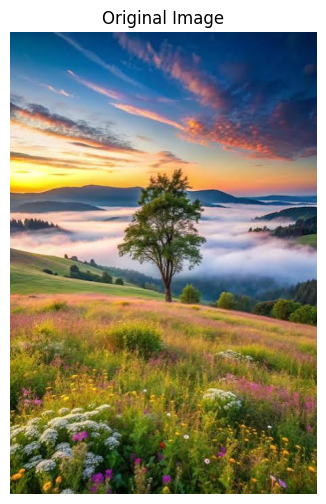

In [3]:
image = cv2.imread(image_name)

if image is None:
    print("Image load nahi hui!")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")
    plt.show()

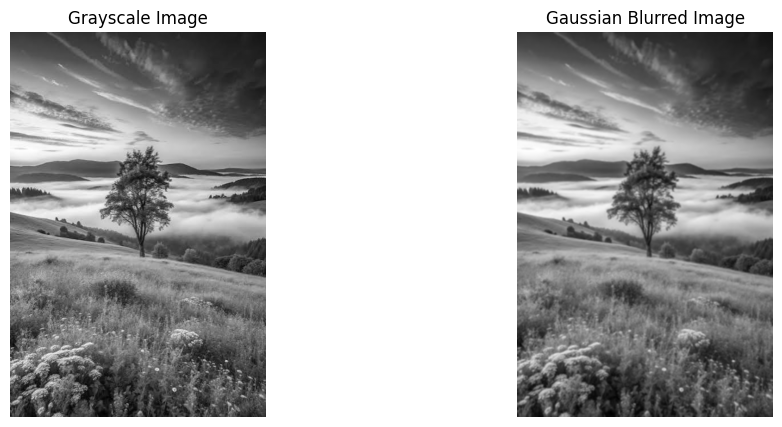

In [4]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

blurred = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blurred Image")
plt.axis("off")

plt.show()

Threshold value: 127


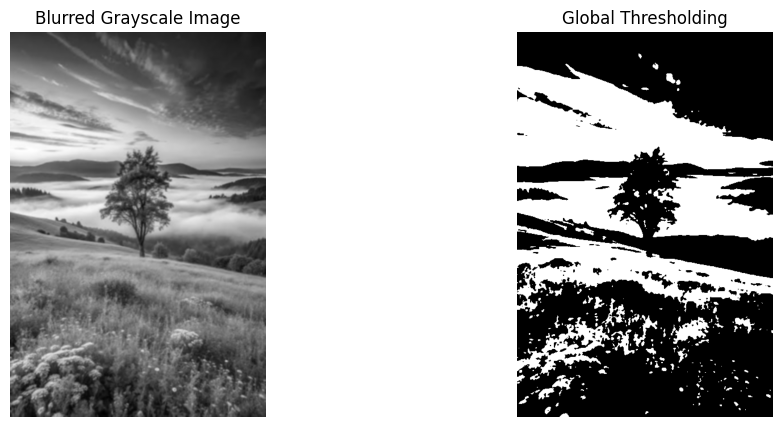

In [5]:
threshold_value = 127

ret, thresh = cv2.threshold(
    blurred,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

print("Threshold value:", threshold_value)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(thresh, cmap="gray")
plt.title("Global Thresholding")
plt.axis("off")

plt.show()

Otsu Threshold Value: 122.0


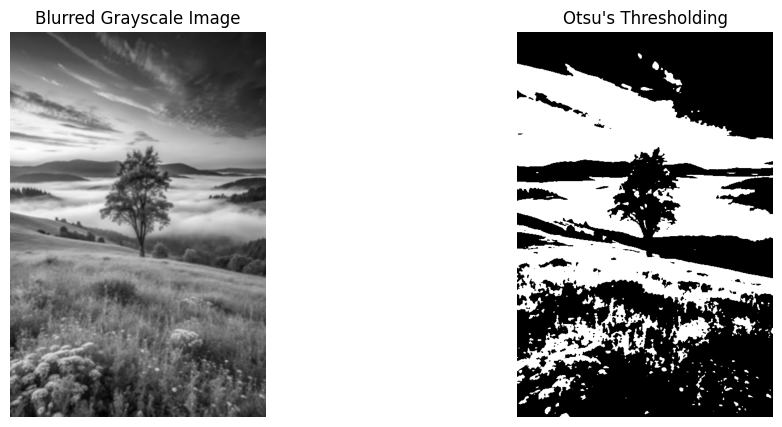

In [6]:
otsu_value, otsu_thresh = cv2.threshold(
    blurred,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold Value:", otsu_value)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(otsu_thresh, cmap="gray")
plt.title("Otsu's Thresholding")
plt.axis("off")

plt.show()

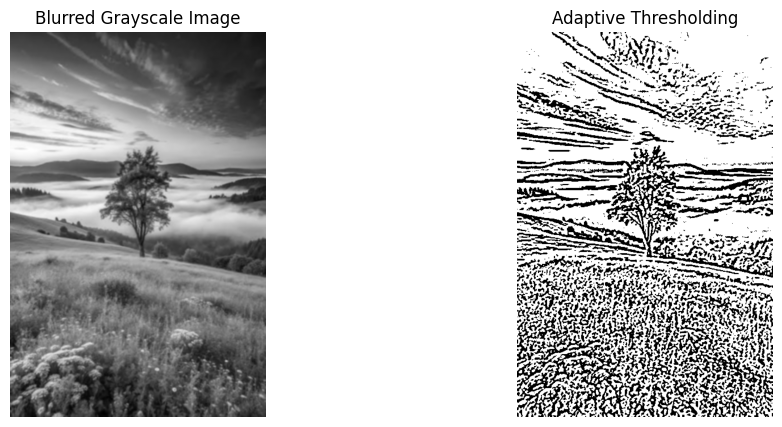

In [7]:
adaptive_thresh = cv2.adaptiveThreshold(
    blurred,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adaptive_thresh, cmap="gray")
plt.title("Adaptive Thresholding")
plt.axis("off")

plt.show()

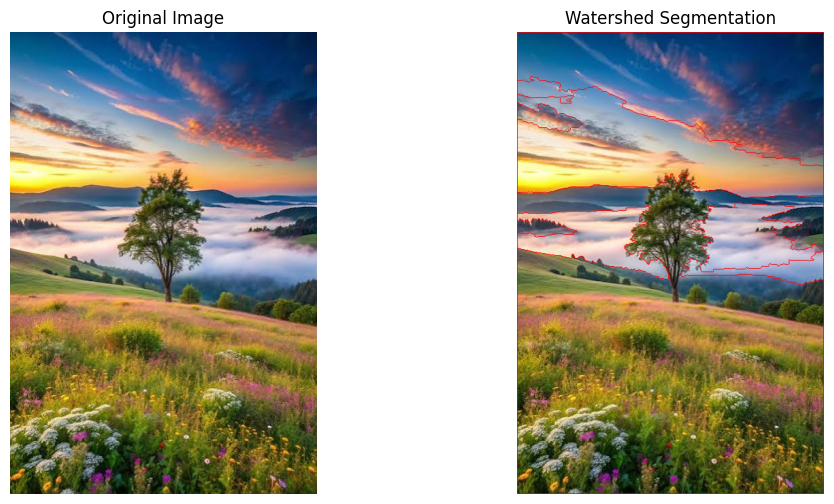

Watershed segmentation completed!


In [8]:
# Convert threshold image to binary
binary = otsu_thresh.copy()

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel,
    iterations=2
)

# Sure background
sure_bg = cv2.dilate(
    opening,
    kernel,
    iterations=3
)

# Distance transform
dist_transform = cv2.distanceTransform(
    opening,
    cv2.DIST_L2,
    5
)

# Sure foreground
ret, sure_fg = cv2.threshold(
    dist_transform,
    0.5 * dist_transform.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Unknown region
unknown = cv2.subtract(
    sure_bg,
    sure_fg
)

# Marker labelling
ret, markers = cv2.connectedComponents(
    sure_fg
)

# Add 1 so background becomes 1
markers = markers + 1

# Mark unknown region as 0
markers[unknown == 255] = 0

# Apply watershed
watershed_image = image.copy()

markers = cv2.watershed(
    watershed_image,
    markers
)

# Watershed boundaries
watershed_image[markers == -1] = [0, 0, 255]

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(watershed_image, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")

plt.show()

print("Watershed segmentation completed!")

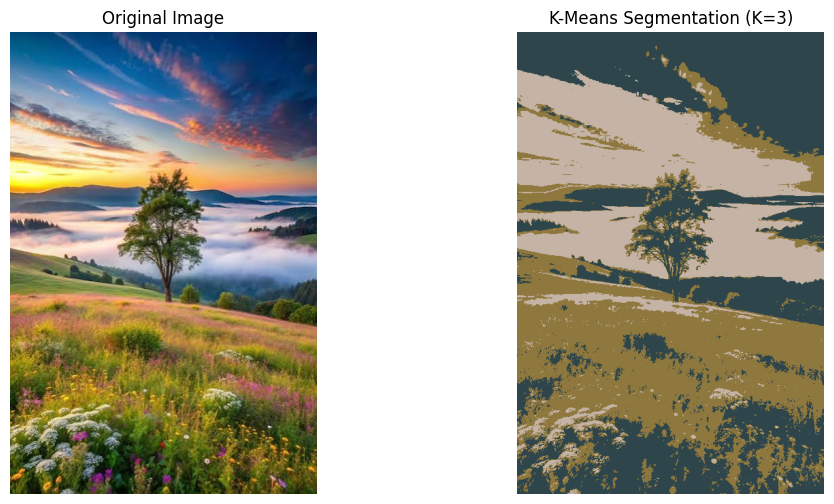

K-Means segmentation completed!
Number of clusters: 3


In [9]:
# Convert image from BGR to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Reshape image pixels into a 2D array
pixel_data = image_rgb.reshape((-1, 3))

# Convert to float32
pixel_data = np.float32(pixel_data)

# Number of clusters
K = 3

# K-Means criteria
criteria = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

# Apply K-Means
compactness, labels, centers = cv2.kmeans(
    pixel_data,
    K,
    None,
    criteria,
    10,
    cv2.KMEANS_RANDOM_CENTERS
)

# Convert centers to uint8
centers = np.uint8(centers)

# Replace each pixel with its cluster center
segmented_data = centers[labels.flatten()]

# Reshape back to original image
segmented_image = segmented_data.reshape(image_rgb.shape)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented_image)
plt.title("K-Means Segmentation (K=3)")
plt.axis("off")

plt.show()

print("K-Means segmentation completed!")
print("Number of clusters:", K)

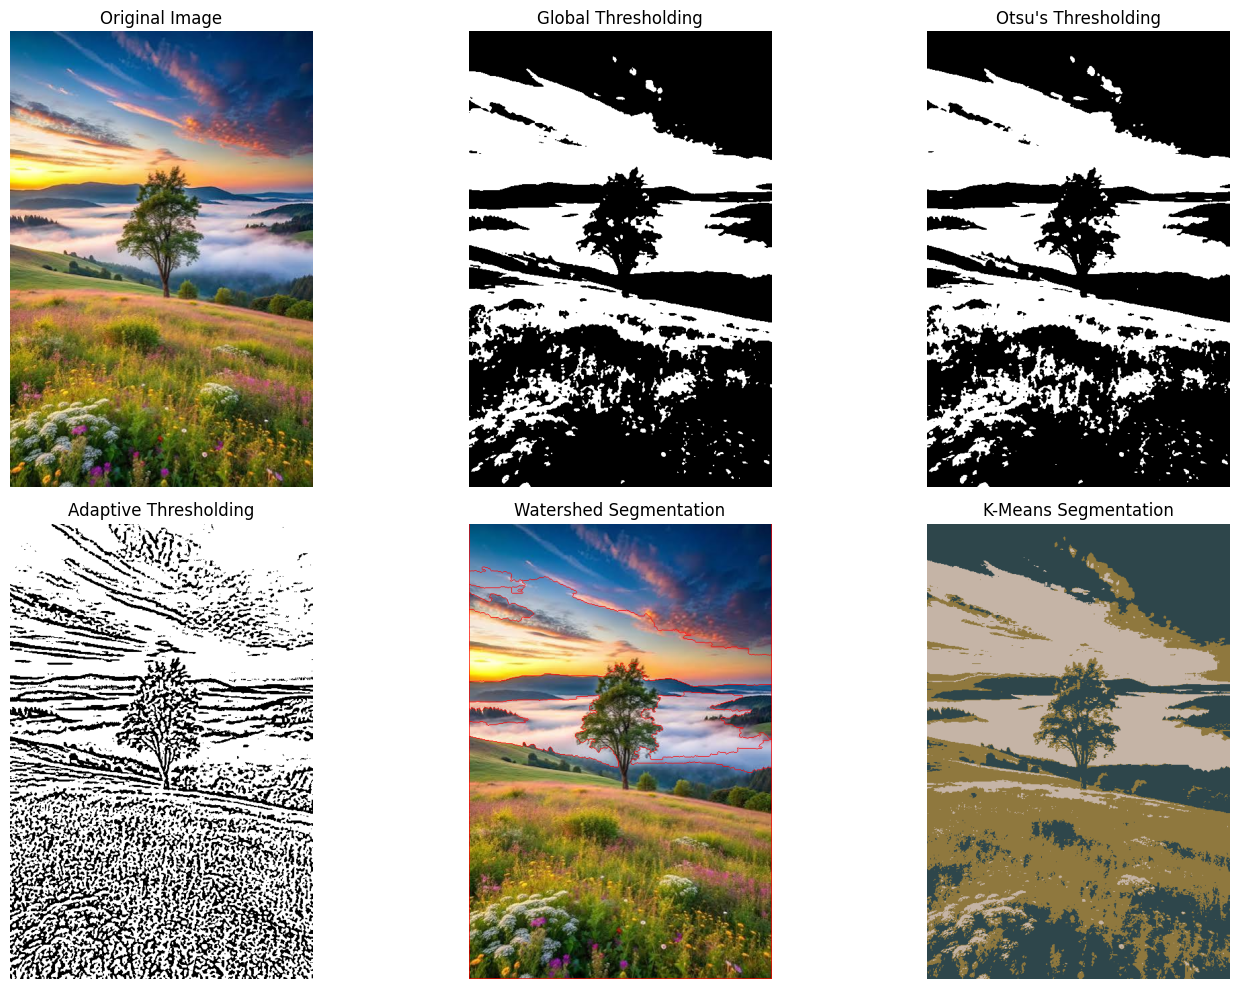

In [10]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(thresh, cmap="gray")
plt.title("Global Thresholding")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(otsu_thresh, cmap="gray")
plt.title("Otsu's Thresholding")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(adaptive_thresh, cmap="gray")
plt.title("Adaptive Thresholding")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(cv2.cvtColor(watershed_image, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(segmented_image)
plt.title("K-Means Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

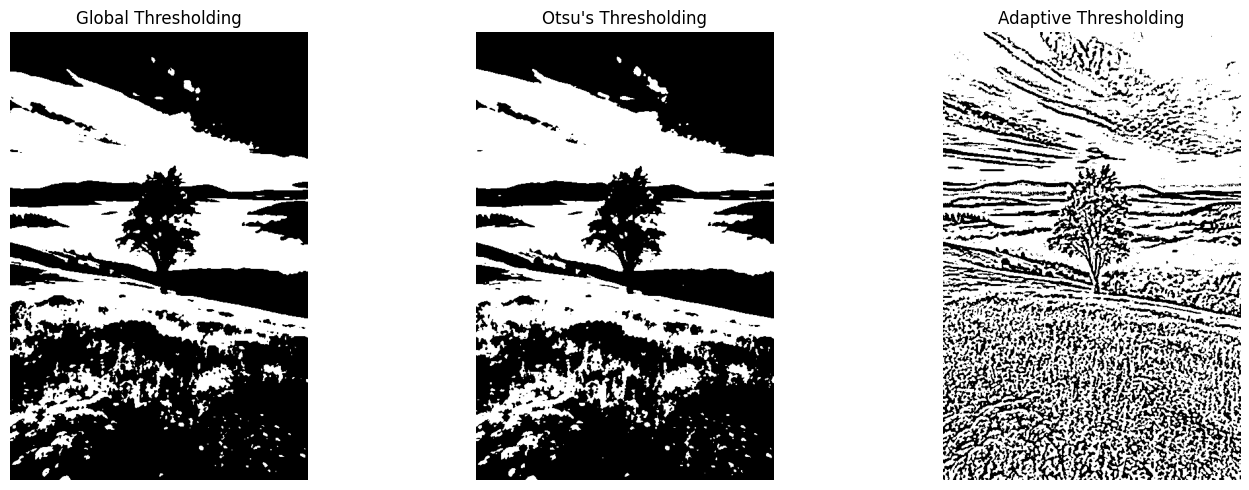

In [11]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(thresh, cmap="gray")
plt.title("Global Thresholding")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(otsu_thresh, cmap="gray")
plt.title("Otsu's Thresholding")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(adaptive_thresh, cmap="gray")
plt.title("Adaptive Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
import pandas as pd

comparison_data = {
    "Technique": [
        "Global Thresholding",
        "Otsu's Thresholding",
        "Adaptive Thresholding",
        "Watershed",
        "K-Means"
    ],

    "Type": [
        "Threshold-based",
        "Threshold-based",
        "Threshold-based",
        "Region-based",
        "Clustering-based"
    ],

    "Main Advantage": [
        "Simple and fast",
        "Automatic threshold",
        "Works with varying illumination",
        "Separates touching objects",
        "Groups similar pixels"
    ],

    "Computational Cost": [
        "Low",
        "Low",
        "Medium",
        "Medium",
        "Higher"
    ]
}

comparison_df = pd.DataFrame(comparison_data)

comparison_df

,Technique,Type,Main Advantage,Computational Cost
0,Global Thresholding,Threshold-based,Simple and fast,Low
1,Otsu's Thresholding,Threshold-based,Automatic threshold,Low
2,Adaptive Thresholding,Threshold-based,Works with varying illumination,Medium
3,Watershed,Region-based,Separates touching objects,Medium
4,K-Means,Clustering-based,Groups similar pixels,Higher


In [13]:
print("K-Means Segmentation Information")
print("--------------------------------")
print("Number of clusters (K):", K)
print("Number of pixels:", pixel_data.shape[0])
print("Number of color channels:", pixel_data.shape[1])

K-Means Segmentation Information
--------------------------------
Number of clusters (K): 3
Number of pixels: 306229
Number of color channels: 3


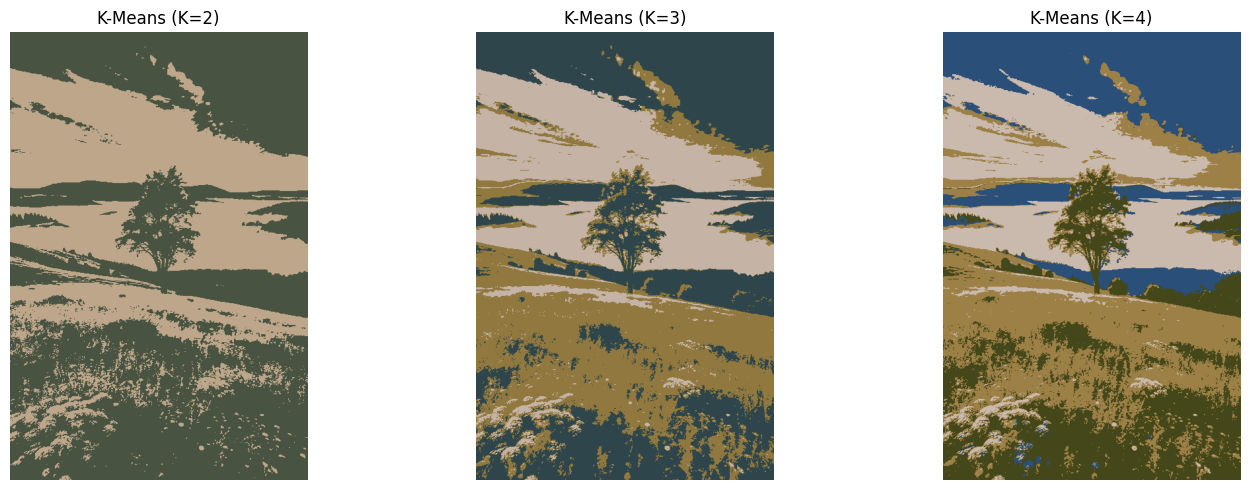

In [14]:
K_values = [2, 3, 4]

plt.figure(figsize=(15, 5))

for i, k in enumerate(K_values):

    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        50,
        0.2
    )

    compactness, labels_k, centers_k = cv2.kmeans(
        pixel_data,
        k,
        None,
        criteria,
        5,
        cv2.KMEANS_RANDOM_CENTERS
    )

    centers_k = np.uint8(centers_k)

    segmented_k = centers_k[
        labels_k.flatten()
    ].reshape(image_rgb.shape)

    plt.subplot(1, 3, i + 1)
    plt.imshow(segmented_k)
    plt.title(f"K-Means (K={k})")
    plt.axis("off")

plt.tight_layout()
plt.show()